In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# parse_date convertit directrmrnt la colonne en vraie dates (datetime)
#ce qui permettera plus loin de regrouper par mois ou par année
df = pd.read_csv("../data/immobilier_transactions.csv", parse_dates=['date_mutation'])

df['prix_m2'] = df['valeur_fonciere'] / df['surface_bati']

df.shape          # nombre de lignes et de colonnes
df.info()         # types des colonnes et valeurs manquantes
df['prix_m2'].describe()   # stats : moyenne, min, max…

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_mutation         6000 non-null   int64         
 1   date_mutation       6000 non-null   datetime64[us]
 2   commune             6000 non-null   str           
 3   code_postal         6000 non-null   int64         
 4   type_local          6000 non-null   str           
 5   surface_bati        6000 non-null   int64         
 6   nb_pieces           6000 non-null   int64         
 7   surface_terrain     6000 non-null   int64         
 8   annee_construction  6000 non-null   int64         
 9   dpe                 6000 non-null   str           
 10  valeur_fonciere     6000 non-null   int64         
 11  prix_m2             6000 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(7), str(3)
memory usage: 671.5 KB


count    6000.000000
mean     2795.302565
std      1100.550483
min       743.055556
25%      1891.304348
50%      2605.950011
75%      3562.500000
max      8029.411765
Name: prix_m2, dtype: float64

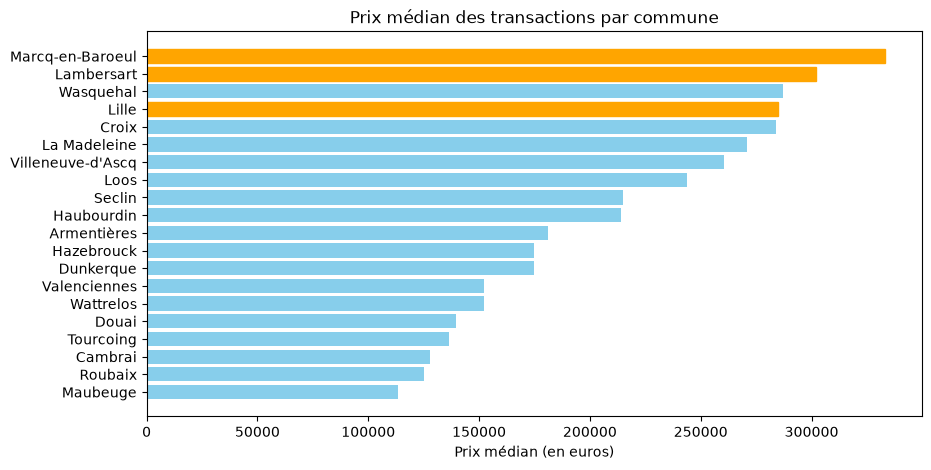

In [24]:
med = df.groupby("commune")["valeur_fonciere"].median().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))

barres = ax.barh(med.index, med.values, color='skyblue')
ax.set_title("Prix médian des transactions par commune")
ax.set_xlabel("Prix médian (en euros)")

for b, nom in zip(barres, med.index):
    if nom in ["Lille", "Lambersart", "Marcq-en-Baroeul"]:
        b.set_color("orange")


## Construire une grille de plusieurs axes


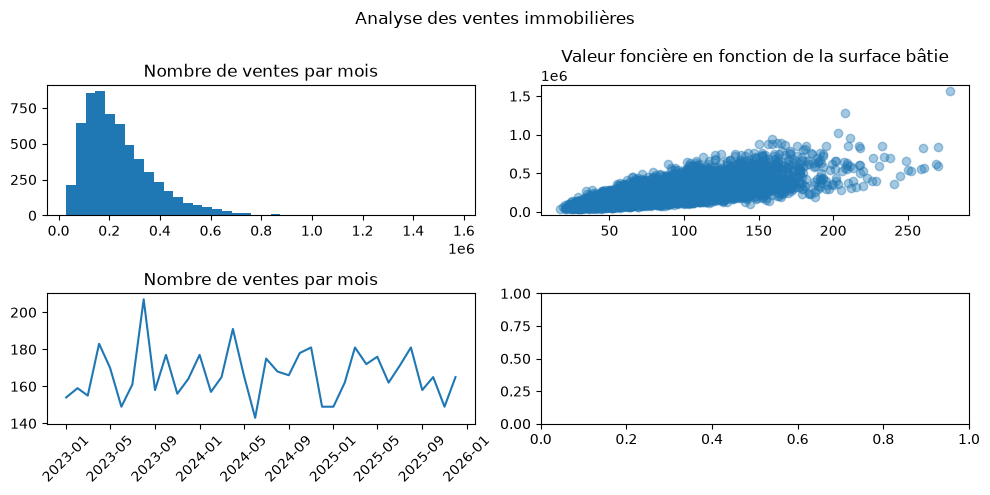

In [49]:
# Donne le nombre de ventes par mois; "MS" regroupe par début de mois (Month Start)
mensuel = df.set_index("date_mutation")["valeur_fonciere"].resample("MS").count()

fig, axes = plt.subplots(2, 2, figsize=(10, 5))
axes[0][0].hist(df['valeur_fonciere'], bins=40)
axes[0, 0].set_title("Nombre de ventes par mois")

axes[0, 1].scatter(df["surface_bati"], df["valeur_fonciere"], alpha=0.4)
axes[0, 1].set_title("Valeur foncière en fonction de la surface bâtie")

axes[1, 0].plot(mensuel.index, mensuel.values)
axes[1, 0].set_title("Nombre de ventes par mois")
axes[1, 0].tick_params(axis='x', rotation=45)


fig.suptitle("Analyse des ventes immobilières")
fig.tight_layout()

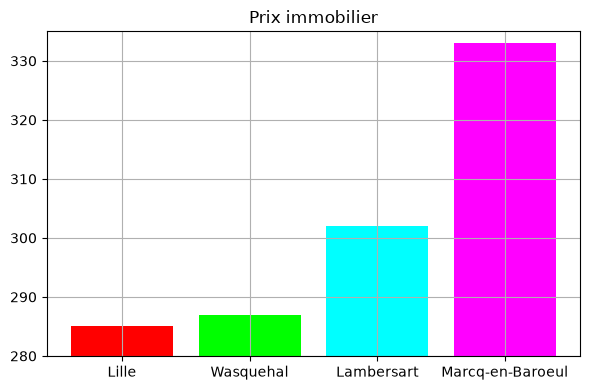

In [63]:
med2 = df.groupby("commune")["valeur_fonciere"].median().sort_values() / 1e3
top4 = med2.tail(4)   # les 4 communes les plus chères, de la moins à la plus chère
 
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(top4.index, top4.values,
       color=["red", "lime", "cyan", "magenta"])   # une couleur par barre,
                                                     # sans aucune signification
ax.set_ylim(280, 335)                               # axe tronqué : ne part pas de 0
ax.set_title("Prix immobilier")                     # titre neutre, ne dit rien
ax.grid(True)                                       # grille partout : encre inutile
fig.tight_layout()
 

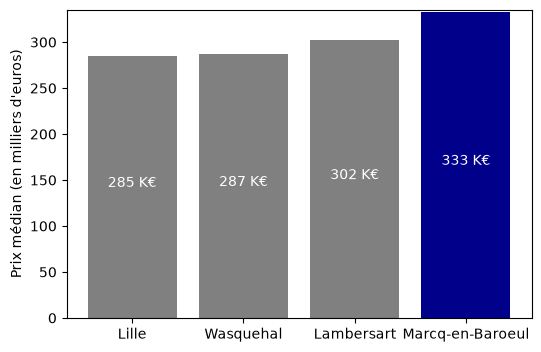

In [73]:
fig, ax = plt.subplots(figsize=(6, 4))

couleurs = ["grey"] * len(top4)   # une couleur unique pour toutes les barres
couleurs[-1] = "darkblue"                  # sauf pour la dernière, qui est rouge

ax.bar(top4.index, top4.values, color=couleurs)
ax.set_ylabel("Prix médian (en milliers d'euros)")
ax.set_ylim(0, 335)     

for commune, valeur in top4.items():
    ax.text(commune, valeur / 2, f"{valeur:.0f} K€", ha='center', color='white', fontsize=10)